# Week 13 Assignment - Timothy Kenney

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

Business Scenario
A university received 17,339 applications across three colleges: Business & Economics, Math & Science, and Arts & Letters.

The university's admissions office wants to understand differences in application volumes, academic performance, and admission outcomes across colleges. As a Business Data Analyst, your task is to analyze the admissions data, identify meaningful patterns, and recommend strategies to improve admission and enrollment planning.

In [4]:
# Step 1: Read Excel file
df = pd.read_excel('applications.xlsx')

# Step 2: Display first 5 rows
print(df.head())
# Step 3: Check missing values
print(df.isnull().sum())
# Step 4: Clean data for applicant analysis
df1 = df.dropna(subset=['Applicant'])
# Step 5: Clean data for college analysis
df2 = df.dropna(subset=['College'])
# Step 6: Display cleaned data
print(df1.head())
print(df2.head())

   Applicant Sex  SAT_ACT               College Admitted Enrolled  \
0          1   M     1460  Business & Economics      Yes       No   
1          2   F     1180        Math & Science       No       No   
2          3   M     1340        Arts & Letters      Yes       No   
3          4   M     1190  Business & Economics       No       No   
4          5   F     1290  Business & Economics       No       No   

   Extracurricular_Hours  
0                      5  
1                     10  
2                      7  
3                      1  
4                      4  
Applicant                0
Sex                      0
SAT_ACT                  0
College                  0
Admitted                 0
Enrolled                 0
Extracurricular_Hours    0
dtype: int64
   Applicant Sex  SAT_ACT               College Admitted Enrolled  \
0          1   M     1460  Business & Economics      Yes       No   
1          2   F     1180        Math & Science       No       No   
2          3  

Task 01: Bar Plot: Compare the number of applications received by each college. Which college attracts the most applicants?

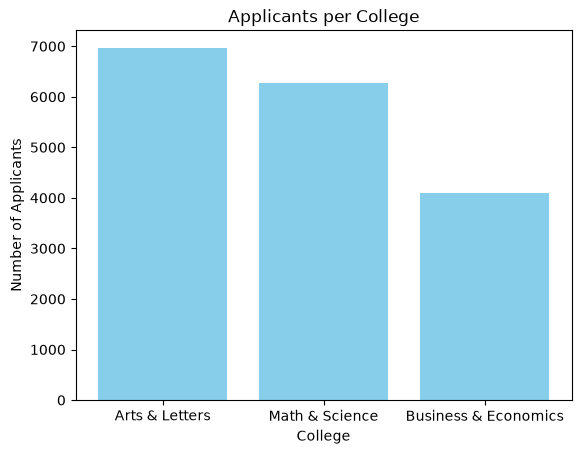

In [5]:
# Matplotlib bar plot

# Step 1: Count applications for each college
Applicants = df2['College'].value_counts()

# Step 2: Create bar plot
plt.bar(Applicants.index, Applicants.values, color='skyblue')

# Step 3: Add title and labels
plt.title('Applicants per College')
plt.xlabel('College')
plt.ylabel('Number of Applicants')

# Step 4: Display chart
plt.show()

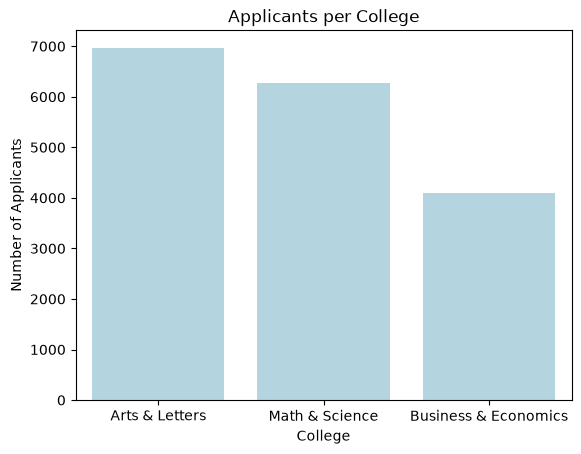

In [15]:
# Seaborn bar plot

# Step 1 Count number of applicants
Applicants = df2['College'].value_counts()

# Step 2: Create bar plot
sns.barplot(x=Applicants.index, y=Applicants.values,
            color='lightblue')

# Step 3: Add title and labels
plt.title('Applicants per College')
plt.xlabel('College')
plt.ylabel('Number of Applicants')

# Step 4: Display chart
plt.show()

In [20]:
# Plotly bar plot

# Step 1: Count applicants by college
Applicants = df2['College'].value_counts()

# Step 2: Create interactive bar plot
fig = px.bar(Applicants, x=Applicants.index, y=Applicants.values,
    color_discrete_sequence=['orange'],
    title='Applicants per College',
)
# Step 3: Add axis labels
fig.update_layout(
    xaxis_title='College',
    yaxis_title='Number of Applicants'
)
# Step 4: Display chart
fig.show()

Task 02: Histogram: Visualize the distribution of SAT_ACT scores. What is the most common score range?

SAT_ACT Class Intervals: [ 280.  500.  720.  940. 1160. 1380. 1600.]
Frequencies: [7.000e+00 9.700e+01 1.602e+03 6.324e+03 7.355e+03 1.954e+03]
Highest Frequency: 7355.0


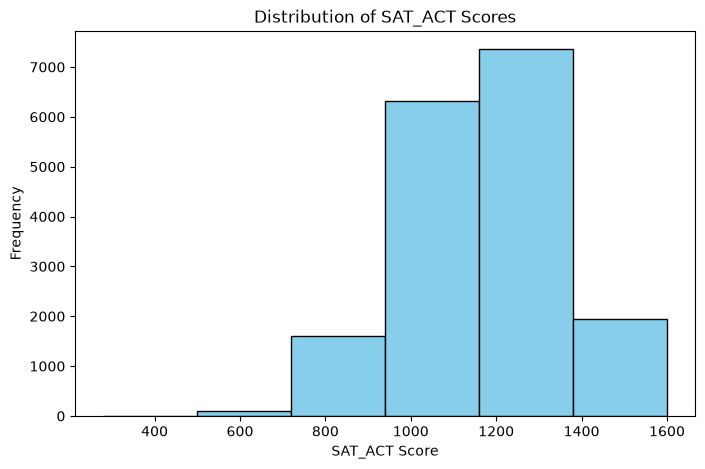

In [8]:
# Matplotlib histogram

# Step 1: Define six class intervals for SAT_ACT scores
bins = [280, 500, 720, 940, 1160, 1380, 1600]

# Step 2: Create histogram and get frequencies
plt.figure(figsize=(8, 5))
frequency, intervals, bars = plt.hist(
    df['SAT_ACT'], bins=bins, color='skyblue', edgecolor='black'
)

# Step 3: Display frequency distribution
print('SAT_ACT Class Intervals:', intervals)
print('Frequencies:', frequency)
print('Highest Frequency:', frequency.max())

# Step 4: Add title and axis labels
plt.title('Distribution of SAT_ACT Scores')
plt.xlabel('SAT_ACT Score')
plt.ylabel('Frequency')

# Step 5: Display chart
plt.show()

SAT_ACT Score Intervals: [ 280  500  720  940 1160 1380 1600]
Frequencies: [   7   97 1602 6324 7355 1954]


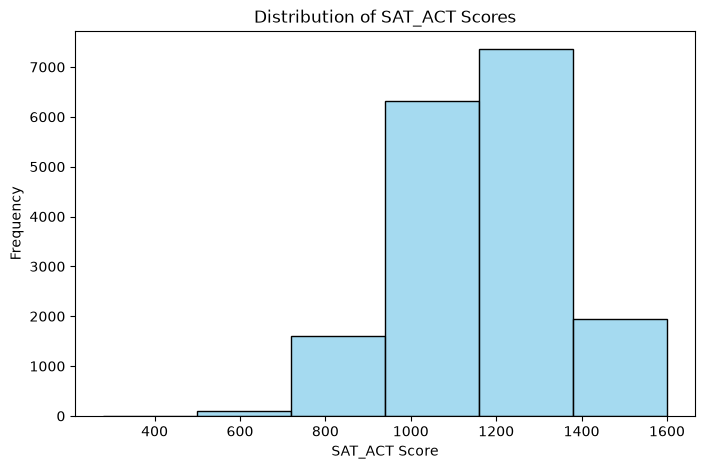

In [21]:

# Seaborn

# Step 1: Define Class Intervals
bins = [280, 500, 720, 940, 1160, 1380, 1600]
frequency, intervals = np.histogram(scores, bins=bins)

# Step 2: Display frequency distribution
print("SAT_ACT Score Intervals:", intervals)
print("Frequencies:", frequency)

# Step 3: Create histogram using Seaborn
plt.figure(figsize=(8, 5))
sns.histplot(data=df, x='SAT_ACT', bins=bins,
             color='skyblue', edgecolor='black')

# Step 4: Add title and axis labels
plt.title('Distribution of SAT_ACT Scores')
plt.xlabel('SAT_ACT Score')
plt.ylabel('Frequency')

# Step 5: Display chart
plt.show()

In [23]:
# Plotly histogram
# Step 1: Define six class intervals
bins = [280, 500, 720, 940, 1160, 1380, 1600]
# Step 2: Calculate frequency distribution
frequency, intervals = np.histogram(df['SAT_ACT'], bins=bins)

# Step 3: Display frequency distribution
print('SAT_ACT Score Intervals:', intervals)
print('Frequencies:', frequency)

# Step 4: Create histogram using Plotly
fig = px.histogram(
    df,
    x='SAT_ACT',
    nbins=6,
    color_discrete_sequence=['blue'],
    title='Distribution of SAT_ACT Scores',
    width=800,
    height=500
)

# Step 5: Set interval width and starting point
fig.update_traces(xbins=dict(start=280, end=1600, size=220))

# Step 6: Add axis labels
fig.update_layout(
    xaxis_title='SAT_ACT Score',
    yaxis_title='Frequency'
)

# Step 7: Display histogram
fig.show()

SAT_ACT Score Intervals: [ 280  500  720  940 1160 1380 1600]
Frequencies: [   7   97 1602 6324 7355 1954]


Task 03: Scatter Plot: Visualize the relationship between SAT_ACT scores and Extracurricular_Hours. Is there a positive, negative, or no clear relationship?

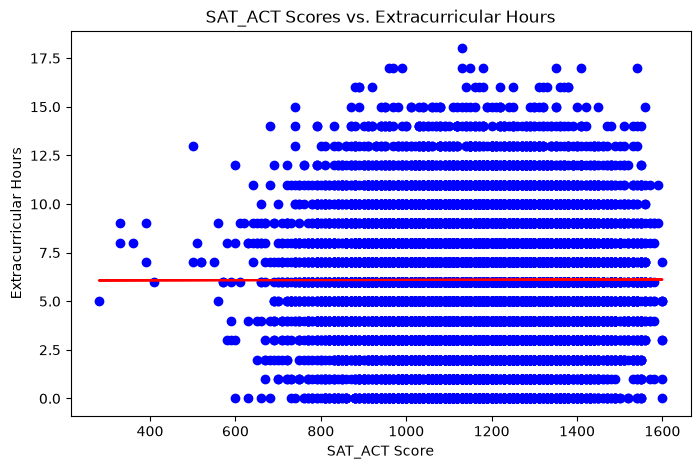

In [11]:
# Matplotlib Scatter

# Step 1: Create a scatter plot
plt.figure(figsize=(8, 5))
plt.scatter(df['SAT_ACT'], df['Extracurricular_Hours'], color='blue')

# Step 2: Add a linear trendline
m, b = np.polyfit(df['SAT_ACT'], df['Extracurricular_Hours'], 1)
plt.plot(df['SAT_ACT'], m * df['SAT_ACT'] + b, color='red')

# Step 3: Add title and axis labels
plt.title('SAT_ACT Scores vs. Extracurricular Hours')
plt.xlabel('SAT_ACT Score')
plt.ylabel('Extracurricular Hours')

# Step 4: Display the scatter plot
plt.show()

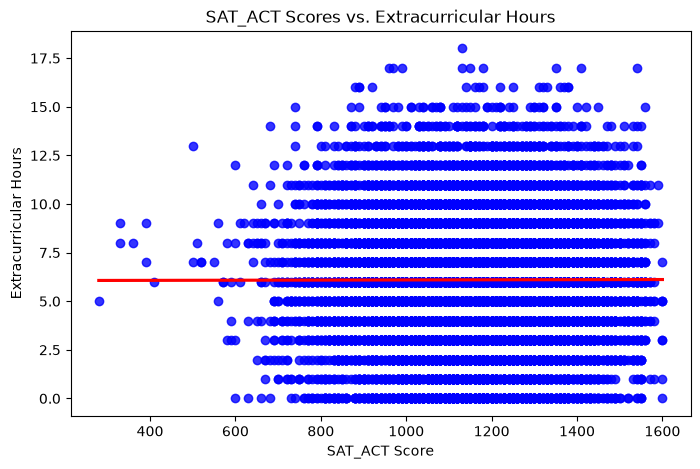

In [12]:

# Seaborn Scatter

# Step 1: Create a scatter plot with a trendline
plt.figure(figsize=(8, 5))
sns.regplot(data=df, x='SAT_ACT', y='Extracurricular_Hours',
            scatter_kws={'color': 'blue'},
            line_kws={'color': 'red'},
            ci=None)

# Step 2: Add title and axis labels
plt.title('SAT_ACT Scores vs. Extracurricular Hours')
plt.xlabel('SAT_ACT Score')
plt.ylabel('Extracurricular Hours')

# Step 3: Display the scatter plot
plt.show()

In [13]:
# Plotly Scatter
# Step 1: Create a scatter plot with a trendline
fig = px.scatter(
    df,
    x='SAT_ACT',
    y='Extracurricular_Hours',
    trendline='ols',
    color_discrete_sequence=['blue'],
    title='SAT_ACT Scores vs. Extracurricular Hours',
    width=800,
    height=500
)

# Step 2: Add axis labels
fig.update_layout(
    xaxis_title='SAT_ACT Score',
    yaxis_title='Extracurricular Hours'
)

# Step 3: Display the scatter plot
fig.show()

Task 04: Data-Driven Insights: Identify three important findings and recommend strategies to improve admission and enrollment planning.

## Task 04: Data-Driven Insights

### 1. Application Volume by College

**Finding:** Arts & Letters receives the highest number of applications, with 6,964 applicants (40.2% of the total). Math & Science follows with 6,272, while Business & Economics receives 4,103.

**Recommendation:** The university should consider application demand when planning admissions staffing, resources, and available enrollment capacity. It could also evaluate recruitment strategies to increase interest in colleges receiving fewer applications.

### 2. SAT_ACT Score Distribution

**Finding:** The most common SAT_ACT score range is 1160–1380, containing 7,355 applicants (42.4% of the total). This indicates that a substantial portion of applicants falls within this academic performance range.

**Recommendation:** The university can use this information to better understand its applicant population, plan academic support resources, and evaluate recruitment strategies. Comparing score distributions across colleges may also help identify differences in the academic profiles of applicants.

### 3. SAT_ACT Scores and Extracurricular Activities

**Finding:** The scatter plots show no clear linear relationship between SAT_ACT scores and extracurricular hours. Applicants with more extracurricular hours do not necessarily have higher academic scores.

**Recommendation:** The university should evaluate academic performance and extracurricular involvement as separate factors rather than assuming one predicts the other. Both may provide useful information during a holistic admissions review, although additional analysis would be needed to determine their relationship with admission and enrollment outcomes.

# Additional Finding

### 4. Admission-to-Enrollment Conversion

**Finding:** Business & Economics has the highest enrollment conversion rate at 30.6%, compared to Arts & Letters at 23.1% and Math & Science at 21.4%. Although Business & Economics receives the fewest applications, a larger percentage of its admitted applicants ultimately enroll. This suggests that application volume does not necessarily translate into higher enrollment rates.

**Recommendation:** The university should investigate why Business & Economics has a higher enrollment conversion rate and identify strategies that could improve enrollment in other colleges. This could include evaluating recruitment practices, financial aid offerings, and communication with admitted students. Improving conversion rates could increase enrollment without requiring additional applications.

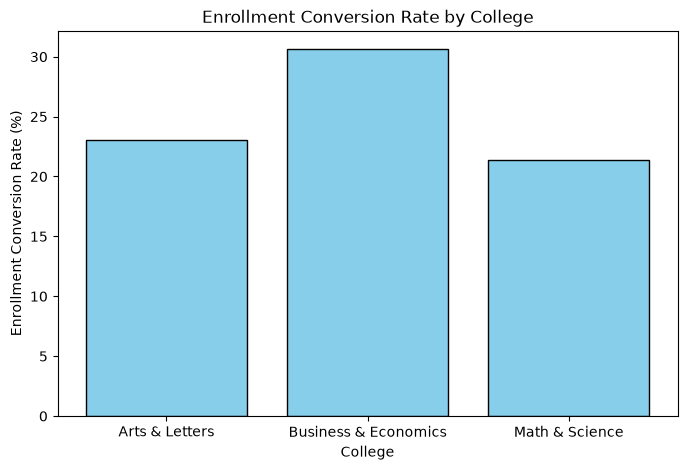

In [14]:
# Matplotlib bar plot

# Step 1: Filter admitted applicants
admitted = df[df['Admitted'] == 'Yes']

# Step 2: Count admitted applicants by college
admitted_counts = admitted['College'].value_counts()

# Step 3: Count enrolled applicants by college
enrolled = admitted[admitted['Enrolled'] == 'Yes']
enrolled_counts = enrolled['College'].value_counts()

# Step 4: Calculate enrollment percentage by college
conversion = (enrolled_counts / admitted_counts) * 100

# Step 5: Create bar plot
plt.figure(figsize=(8, 5))
plt.bar(conversion.index, conversion.values,
        color='skyblue', edgecolor='black')

# Step 6: Add title and axis labels
plt.title('Enrollment Conversion Rate by College')
plt.xlabel('College')
plt.ylabel('Enrollment Conversion Rate (%)')

# Step 7: Display chart
plt.show()